# Práctica 5 — Red neuronal densa con Fashion-MNIST (prendas de vestir)

**Objetivo de esta práctica:** reutilizar la misma red de la práctica 4, pero ahora para clasificar imágenes de **prendas de vestir** en 10 categorías (camiseta, pantalón, zapatilla, etc.).

Fashion-MNIST tiene el mismo formato que MNIST (imágenes de 28 × 28 en escala de grises), por eso el código es casi igual. La diferencia es que aquí las etiquetas se traducen a nombres de prendas, se revisan varias predicciones a la vez y se mide la precisión global con `evaluate`.

## 1. Importar librerías

In [1]:
import tensorflow as tf                                # TensorFlow: para construir y entrenar la red neuronal
import matplotlib.pyplot as plt                        # Para mostrar las imágenes de las prendas
from tensorflow.keras.datasets import fashion_mnist    # Dataset Fashion-MNIST: prendas de vestir (70 000 imágenes)

## 2. Cargar el dataset

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 13s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


## 3. Explorar la forma de los datos

In [3]:
print("Forma de la imagen:", x_test[0].shape)
print("Forma de x_train:", x_train.shape)
print("Forma de x_test:", x_test.shape)
print("Total de muestras:", (len(y_train) + len(y_test)))

Forma de la imagen: (28, 28)
Forma de x_train: (60000, 28, 28)
Forma de x_test: (10000, 28, 28)
Total de muestras: 70000


## 4. Visualizar las primeras 10 imágenes de prueba con su etiqueta

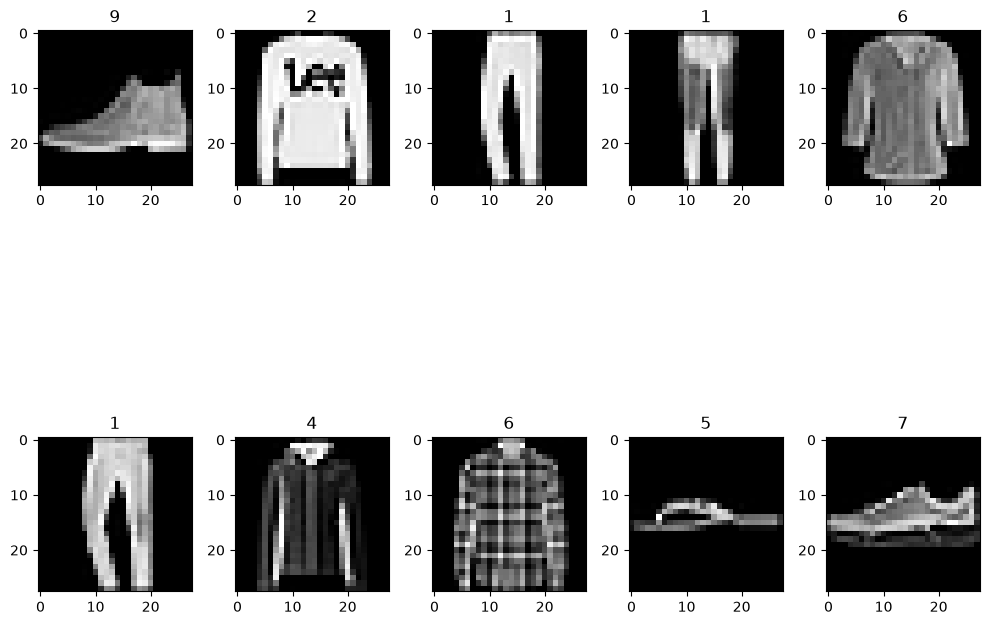

In [4]:
plt.figure(figsize=(10, 10))
for s in range(10):
    plt.subplot(2, 5, s + 1)
    plt.imshow(x_test[s], cmap="gray")
    plt.title(y_test[s])                      # Por ahora la etiqueta es solo un número (0 al 9)
plt.tight_layout()

## 5. Normalizar los píxeles (0 a 1)

In [5]:
x_train = x_train / 255.0
x_test = x_test / 255.0

## 6. Construir el modelo

Misma arquitectura que en MNIST: `Flatten` → `Dense(128, relu)` → `Dense(10, softmax)`.

In [6]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),        # Convierte la imagen 2D en un vector plano
    tf.keras.layers.Dense(128, activation="relu"),        # Capa oculta: 128 neuronas
    tf.keras.layers.Dense(10, activation="softmax")       # Capa de salida: 10 probabilidades (una por prenda)
])

c:\Users\ANT DOR\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7. Compilar y entrenar (15 épocas)

In [7]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=15)

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8267 - loss: 0.4988
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8657 - loss: 0.3753
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8783 - loss: 0.3365
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8843 - loss: 0.3136
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8923 - loss: 0.2941
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8948 - loss: 0.2807
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9014 - loss: 0.2663
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9052 - loss: 0.2565
Epoch 9/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9073 - loss: 0.2464
Epoch 10/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9115 - loss: 0.2366
Epoch 11/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9145 - loss: 0.2292
Epoch 12/15
1875/1875 ━━━━━━━━

## 8. Nombres de las clases

Las etiquetas del dataset son números del 0 al 9. Esta lista permite traducir cada número al nombre de la prenda.

In [8]:
class_names = [
    "T-shirt/top (Camiseta)", "Trouser (Pantalón)", "Pullover (Pulóver)",
    "Dress (Vestido)", "Coat (Abrigo)", "Sandal (Sandalia)",
    "Shirt (Camisa)", "Sneaker (Zapatilla)", "Bag (Bolso)", "Ankle boot (Botín)"
]
print(class_names[0])

T-shirt/top (Camiseta)


## 9. Predecir una prenda

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
Salida de probabilidades de nuestro softmax: [[2.4445418e-08 7.1766914e-19 3.8637177e-10 1.2502189e-18 1.4563264e-12
  1.0000000e+00 1.5516760e-10 5.3819967e-08 1.4146856e-10 6.7777062e-16]]
Afinando la salida: [5] Sandal (Sandalia)
Etiqueta real: 5 Sandal (Sandalia)


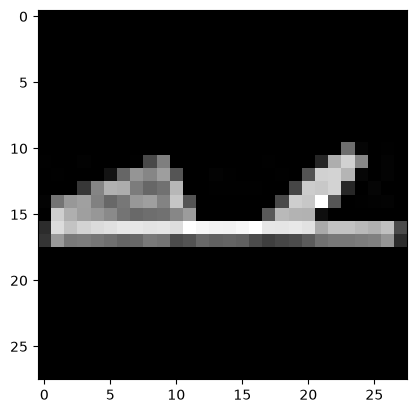

In [9]:
muestra = x_test[111].reshape(1, 28, 28)
predict = model.predict(muestra)

print("Salida de probabilidades de nuestro softmax:", predict)
print("Afinando la salida:", predict.argmax(1), class_names[predict.argmax(1)[0]])
print("Etiqueta real:", y_test[111], class_names[y_test[111]])
plt.imshow(muestra.reshape(28, 28), cmap="gray")

## 10. Predecir 10 prendas a la vez

Se toman las imágenes 111 a 120, se predicen todas juntas y se compara la predicción con la etiqueta real de cada una.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
--- Prenda 111 ---
Afinando la salida: 5 Sandal (Sandalia)
Etiqueta real: 5 Sandal (Sandalia)
------------------------------
--- Prenda 112 ---
Afinando la salida: 7 Sneaker (Zapatilla)
Etiqueta real: 7 Sneaker (Zapatilla)
------------------------------
--- Prenda 113 ---
Afinando la salida: 0 T-shirt/top (Camiseta)
Etiqueta real: 0 T-shirt/top (Camiseta)
------------------------------
--- Prenda 114 ---
Afinando la salida: 5 Sandal (Sandalia)
Etiqueta real: 5 Sandal (Sandalia)
------------------------------
--- Prenda 115 ---
Afinando la salida: 2 Pullover (Pulóver)
Etiqueta real: 2 Pullover (Pulóver)
------------------------------
--- Prenda 116 ---
Afinando la salida: 8 Bag (Bolso)
Etiqueta real: 8 Bag (Bolso)
------------------------------
--- Prenda 117 ---
Afinando la salida: 6 Shirt (Camisa)
Etiqueta real: 6 Shirt (Camisa)
------------------------------
--- Prenda 118 ---
Afinando la salida: 7 Sneaker (Zapatilla)
Etiqueta real: 7 Sneaker (Za

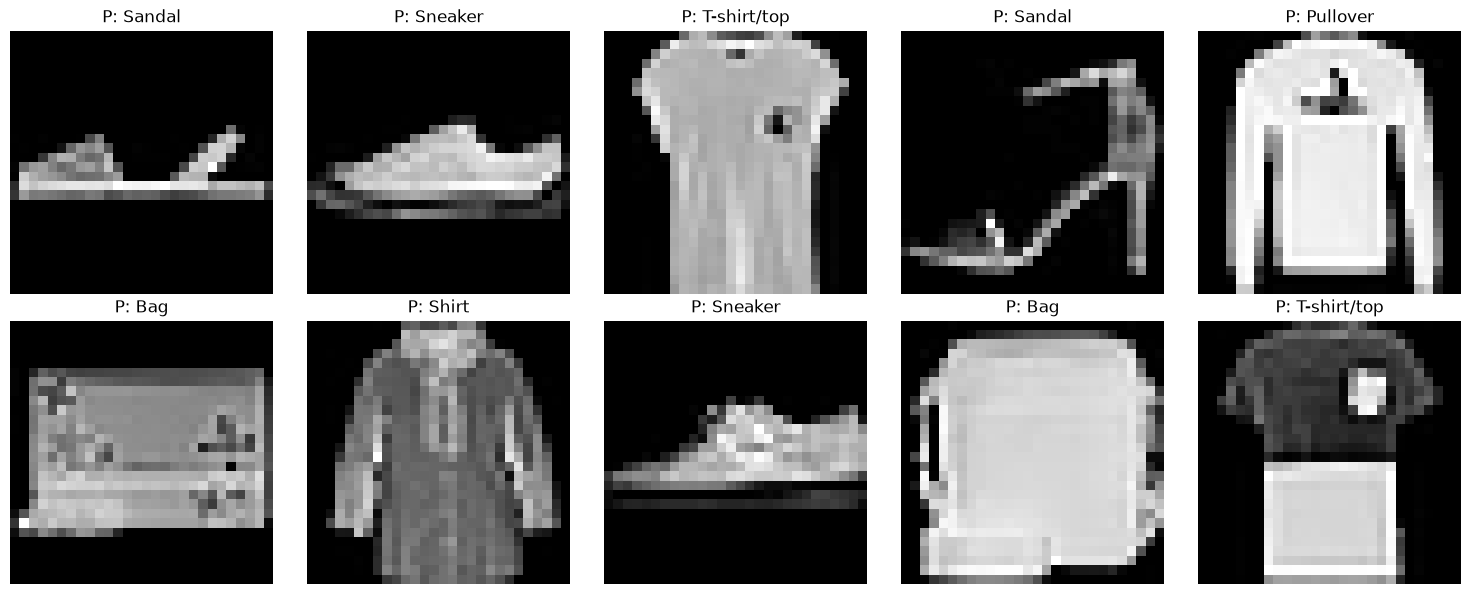

In [10]:
muestras = x_test[111:121]
predicts = model.predict(muestras)
indices_predicciones = predicts.argmax(1)

for i in range(10):
    idx_real = y_test[111 + i]               # Índice real de cada prenda
    idx_pred = indices_predicciones[i]       # Índice predicho por el modelo

    print(f"--- Prenda {111 + i} ---")
    print("Afinando la salida:", idx_pred, class_names[idx_pred])
    print("Etiqueta real:", idx_real, class_names[idx_real])
    print("-" * 30)

plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(muestras[i], cmap="gray")
    plt.title(f"P: {class_names[indices_predicciones[i]].split(' ')[0]}")   # P: prenda predicha
    plt.axis("off")
plt.tight_layout()
plt.show()

## 11. Precisión global con los datos de prueba

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"El modelo tiene una precisión global del: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8858 - loss: 0.3482
El modelo tiene una precisión global del: 88.58%


## 🗒️ Conclusión

La misma red que reconoce dígitos sirve para clasificar prendas, aunque con menor precisión, porque algunas prendas se parecen mucho entre sí (camisa, camiseta y pulóver). `evaluate` permite medir el desempeño con datos que la red nunca vio durante el entrenamiento.